# ♻️ EcoScan · Clasificación de residuos con modelos preentrenados
### IA Generativa para la Gestión Industrial · Proyecto grupal

**Problema:** separar mal los residuos contamina las cargas de reciclaje. Queremos que una persona suba la foto de un residuo y la app le diga de qué material es, con qué confianza, y le dé una recomendación.

Flujo: 📷 Foto → 🧠 Modelo preentrenado → 📊 Probabilidades → 💬 Gemini → ✅ Recomendación

Este notebook **entrena y evalúa** el modelo. La app (`app.py`) solo carga el archivo `modelo.pt` que se exporta al final.

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

## 0. Librerías

In [1]:
!pip install -q timm                                   # timm: modelos preentrenados (EfficientNet, ResNet...)

import os, shutil, hashlib, json, zipfile, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, timm
from PIL import Image
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from huggingface_hub import hf_hub_download

SEMILLA = 42                                            # para que los resultados se puedan repetir
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DISP = "cuda" if torch.cuda.is_available() else "cpu"   # usa la GPU si existe
print("Dispositivo:", DISP)

Dispositivo: cuda


## 1. Datos

| Aspecto | Detalle |
|---|---|
| Dataset | **TrashNet** · https://huggingface.co/datasets/garythung/trashnet |
| Autores | Gary Thung y Mindy Yang (proyecto Stanford CS229) · https://github.com/garythung/trashnet |
| Licencia | MIT |
| Cómo se obtuvo | Fotos de un objeto sobre cartulina blanca, tomadas con iPhone, con luz natural y/o de interior |
| Clases | `cardboard` (cartón), `glass` (vidrio), `metal`, `paper` (papel), `plastic` (plástico), `trash` (otros residuos) |

Usamos el archivo `dataset-resized.zip` (fotos de 512×384).

In [2]:
zip_path = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")  # descarga (~43 MB)
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/trashnet")                   # descomprime

CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
filas = []
for raiz, _, archivos in os.walk("/content/trashnet"):
    clase = os.path.basename(raiz)
    if clase not in CLASES or "__MACOSX" in raiz:       # ignora carpetas basura de macOS
        continue
    for a in archivos:
        if a.lower().endswith(".jpg"):
            ruta = os.path.join(raiz, a)
            huella = hashlib.md5(open(ruta, "rb").read()).hexdigest()   # "huella" para detectar fotos repetidas
            filas.append({"ruta": ruta, "clase": clase, "huella": huella})
df = pd.DataFrame(filas)
print("Fotos encontradas:", len(df))

dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Fotos encontradas: 2527


**Limpieza:** si la misma foto aparece dos veces la dejamos una sola vez; si aparece con **dos etiquetas distintas** no sabemos cuál es la correcta y la eliminamos.

Fotos contradictorias eliminadas: 3
Fotos únicas usadas: 2521


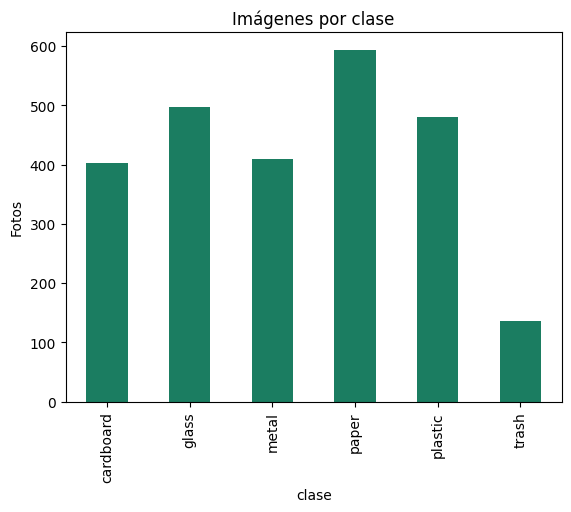

clase
cardboard    403
glass        498
metal        409
paper        594
plastic      480
trash        137
Name: count, dtype: int64


In [3]:
etiquetas_por_foto = df.groupby("huella").clase.nunique()
contradictorias = etiquetas_por_foto[etiquetas_por_foto > 1].index        # misma foto, distinta clase
df = df[~df.huella.isin(contradictorias)].drop_duplicates("huella")        # quita contradicciones y repetidas
print("Fotos contradictorias eliminadas:", len(contradictorias))
print("Fotos únicas usadas:", len(df))

conteo = df.clase.value_counts().reindex(CLASES)
conteo.plot.bar(color="#1b7d61", title="Imágenes por clase"); plt.ylabel("Fotos"); plt.show()
print(conteo)

**Desbalance:** `trash` tiene muchas menos fotos que `paper`. Por eso:
1. medimos **accuracy balanceada** (promedio del acierto de cada clase), no solo accuracy;
2. entrenamos con una **pérdida ponderada** que castiga más los errores en las clases chicas.

**Limitaciones de los datos:** una sola fuente, todas con fondo blanco y buena luz, un objeto por foto. En la vida real (basura sucia, fondos desordenados, varios objetos) el modelo probablemente rinda peor.

### División entrenamiento / validación / prueba (70 / 15 / 15)
Estratificada: cada parte mantiene la proporción de clases. **Validación** sirve para elegir el modelo; **prueba** se usa una sola vez al final.

In [4]:
train, resto = train_test_split(df, test_size=0.30, stratify=df.clase, random_state=SEMILLA)
val, test = train_test_split(resto, test_size=0.50, stratify=resto.clase, random_state=SEMILLA)

DATOS = "/content/datos"                                # carpetas datos/train/<clase>/foto.jpg
shutil.rmtree(DATOS, ignore_errors=True)
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    for _, fila in parte.iterrows():
        destino = f"{DATOS}/{nombre}/{fila.clase}"
        os.makedirs(destino, exist_ok=True)
        shutil.copy(fila.ruta, destino)

conteos = pd.DataFrame({"train": train.clase.value_counts(), "val": val.clase.value_counts(),
                        "test": test.clase.value_counts()}).reindex(CLASES)
conteos

,train,val,test
clase,,,
cardboard,282,60,61
glass,348,75,75
metal,286,61,62
paper,416,89,89
plastic,336,72,72
trash,96,21,20


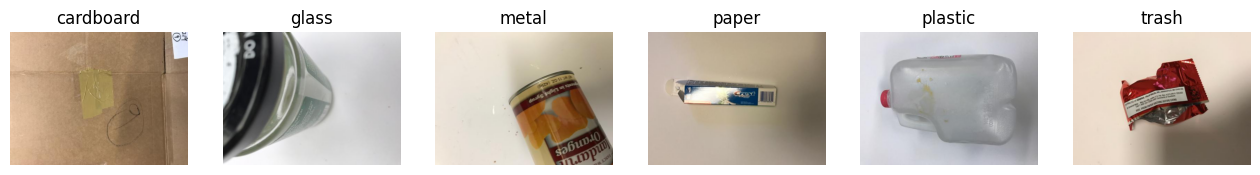

In [5]:
fig, ejes = plt.subplots(1, 6, figsize=(16, 3))
for eje, clase in zip(ejes, CLASES):
    eje.imshow(Image.open(train[train.clase == clase].ruta.iloc[0])); eje.set_title(clase); eje.axis("off")
plt.show()

## 2. Línea base: CLIP sin entrenar (zero-shot)
CLIP compara la foto con frases que nosotros escribimos y elige la más parecida. **No se entrena con nuestras fotos.** Si un modelo entrenado no le gana a esto, entrenar no valió la pena.

In [6]:
from transformers import pipeline
clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32",
                device=0 if DISP == "cuda" else -1)
FRASES = {"cardboard": "a photo of cardboard", "glass": "a photo of a glass bottle or jar",
          "metal": "a photo of a metal can", "paper": "a photo of paper",
          "plastic": "a photo of a plastic bottle or container", "trash": "a photo of garbage"}
FRASE_A_CLASE = {v: k for k, v in FRASES.items()}

def evaluar_clip(parte):
    reales, preds = [], []
    for _, fila in parte.iterrows():
        mejor = clip(fila.ruta, candidate_labels=list(FRASES.values()))[0]["label"]   # frase con mayor puntaje
        reales.append(CLASES.index(fila.clase)); preds.append(CLASES.index(FRASE_A_CLASE[mejor]))
    return np.array(reales), np.array(preds)

y_val_clip, p_val_clip = evaluar_clip(val)
y_test_clip, p_test_clip = evaluar_clip(test)
print(f"CLIP · accuracy balanceada en validación: {balanced_accuracy_score(y_val_clip, p_val_clip):.1%}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


CLIP · accuracy balanceada en validación: 63.8%


## 3. Transfer learning con timm: EfficientNet-B0 vs ResNet18
Tomamos dos redes preentrenadas en ImageNet, **cambiamos su última capa a 6 clases** y las ajustamos con nuestras fotos con una tasa de aprendizaje pequeña (para no "olvidar" lo que ya saben).

- **EfficientNet-B0**: el modelo visto en clase, liviano (~16 MB).
- **ResNet18**: otra arquitectura clásica, para comparar.

Las dos se entrenan con **la misma función**, los mismos datos y se comparan con la misma métrica.

In [7]:
def entrenar(nombre, epocas=8, paciencia=3):
    torch.manual_seed(SEMILLA)
    modelo = timm.create_model(nombre, pretrained=True, num_classes=6).to(DISP)       # salida → 6 clases
    config = timm.data.resolve_model_data_config(modelo)                               # tamaño y normalización del modelo
    prep_train = timm.data.create_transform(**config, is_training=True)               # con aumento de datos
    prep_eval = timm.data.create_transform(**config, is_training=False)               # sin aumento
    dl_train = DataLoader(ImageFolder(f"{DATOS}/train", prep_train), batch_size=32, shuffle=True, num_workers=2)

    pesos = torch.tensor((conteos.train.sum() / (6 * conteos.train)).values, dtype=torch.float32).to(DISP)
    perdida = torch.nn.CrossEntropyLoss(weight=pesos)                                  # pérdida ponderada por clase
    opt = torch.optim.AdamW(modelo.parameters(), lr=1e-4)

    mejor, sin_mejora, historial = -1, 0, []
    for epoca in range(epocas):
        modelo.train()
        for x, y in dl_train:
            opt.zero_grad()
            l = perdida(modelo(x.to(DISP)), y.to(DISP))
            l.backward(); opt.step()
        y_val, probs_val = predecir(modelo, prep_eval, "val")
        score = balanced_accuracy_score(y_val, probs_val.argmax(1))
        historial.append(score)
        print(f"{nombre} · época {epoca + 1} · pérdida {l.item():.3f} · acc. balanceada val {score:.1%}")
        if score > mejor:                                                              # guarda la mejor época
            mejor, sin_mejora = score, 0
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:                                                # parada temprana
                print("Parada temprana: la validación dejó de mejorar"); break
    modelo.load_state_dict(mejores_pesos)
    return {"modelo": modelo, "prep": prep_eval, "config": config, "val": mejor, "historial": historial}


@torch.no_grad()
def predecir(modelo, prep, parte):
    modelo.eval()
    dl = DataLoader(ImageFolder(f"{DATOS}/{parte}", prep), batch_size=64, num_workers=2)
    reales, probs = [], []
    for x, y in dl:
        probs.append(modelo(x.to(DISP)).softmax(1).cpu()); reales.append(y)
    return torch.cat(reales).numpy(), torch.cat(probs).numpy()

In [8]:
resultados = {nombre: entrenar(nombre) for nombre in ["efficientnet_b0", "resnet18"]}

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_b0 · época 1 · pérdida 0.524 · acc. balanceada val 68.7%
efficientnet_b0 · época 2 · pérdida 1.390 · acc. balanceada val 74.4%
efficientnet_b0 · época 3 · pérdida 0.628 · acc. balanceada val 79.6%
efficientnet_b0 · época 4 · pérdida 0.227 · acc. balanceada val 79.2%
efficientnet_b0 · época 5 · pérdida 0.992 · acc. balanceada val 82.1%
efficientnet_b0 · época 6 · pérdida 2.999 · acc. balanceada val 84.6%
efficientnet_b0 · época 7 · pérdida 0.506 · acc. balanceada val 84.0%
efficientnet_b0 · época 8 · pérdida 0.807 · acc. balanceada val 84.8%


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet18 · época 1 · pérdida 1.774 · acc. balanceada val 46.8%
resnet18 · época 2 · pérdida 1.348 · acc. balanceada val 61.2%
resnet18 · época 3 · pérdida 1.259 · acc. balanceada val 67.4%
resnet18 · época 4 · pérdida 1.313 · acc. balanceada val 72.1%
resnet18 · época 5 · pérdida 1.030 · acc. balanceada val 77.1%
resnet18 · época 6 · pérdida 0.778 · acc. balanceada val 75.9%
resnet18 · época 7 · pérdida 0.840 · acc. balanceada val 77.3%
resnet18 · época 8 · pérdida 1.639 · acc. balanceada val 79.9%


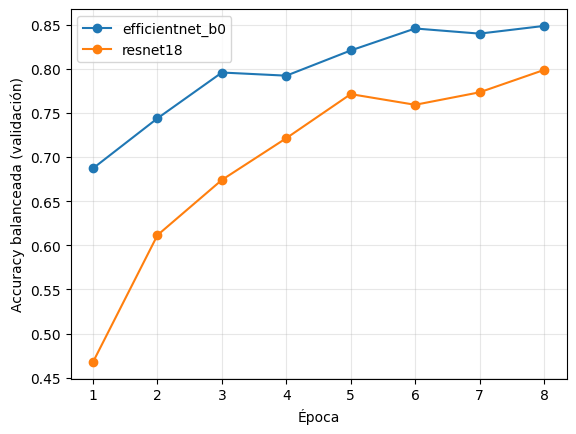

In [9]:
for nombre, r in resultados.items():
    plt.plot(range(1, len(r["historial"]) + 1), r["historial"], marker="o", label=nombre)
plt.xlabel("Época"); plt.ylabel("Accuracy balanceada (validación)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. Elección del modelo y evaluación en prueba
**Elegimos con validación** (antes de mirar prueba) y después reportamos prueba para todos los enfoques.

Modelo elegido por validación: efficientnet_b0


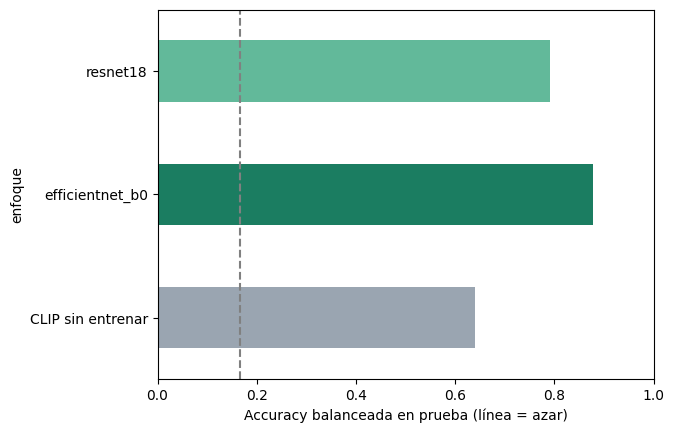

,enfoque,acc_balanceada_val,accuracy_prueba,acc_balanceada_prueba
0,CLIP sin entrenar,0.6382,0.6966,0.6393
1,efficientnet_b0,0.8484,0.8786,0.8778
2,resnet18,0.7985,0.7863,0.7915


In [10]:
elegido = max(resultados, key=lambda n: resultados[n]["val"])
print("Modelo elegido por validación:", elegido)

filas = [{"enfoque": "CLIP sin entrenar",
          "acc_balanceada_val": balanced_accuracy_score(y_val_clip, p_val_clip),
          "accuracy_prueba": accuracy_score(y_test_clip, p_test_clip),
          "acc_balanceada_prueba": balanced_accuracy_score(y_test_clip, p_test_clip)}]
for nombre, r in resultados.items():
    y, probs = predecir(r["modelo"], r["prep"], "test")
    r["y_test"], r["probs_test"] = y, probs
    filas.append({"enfoque": nombre, "acc_balanceada_val": r["val"],
                  "accuracy_prueba": accuracy_score(y, probs.argmax(1)),
                  "acc_balanceada_prueba": balanced_accuracy_score(y, probs.argmax(1))})
comparacion = pd.DataFrame(filas).round(4)
comparacion.set_index("enfoque").acc_balanceada_prueba.plot.barh(color=["#9aa5b1", "#1b7d61", "#62b99a"])
plt.axvline(1/6, ls="--", color="gray"); plt.xlabel("Accuracy balanceada en prueba (línea = azar)"); plt.xlim(0, 1); plt.show()
comparacion

              precision    recall  f1-score   support

   cardboard      0.894     0.967     0.929        61
       glass      0.899     0.947     0.922        75
       metal      0.855     0.855     0.855        62
       paper      0.915     0.843     0.877        89
     plastic      0.921     0.806     0.859        72
       trash      0.630     0.850     0.723        20

    accuracy                          0.879       379
   macro avg      0.852     0.878     0.861       379
weighted avg      0.884     0.879     0.879       379



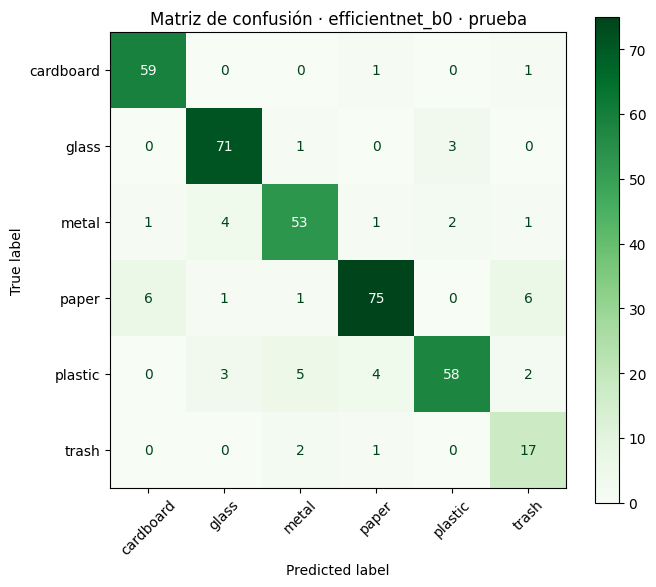

In [11]:
y_test, probs_test = resultados[elegido]["y_test"], resultados[elegido]["probs_test"]
pred_test = probs_test.argmax(1)
print(classification_report(y_test, pred_test, target_names=CLASES, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=CLASES).plot(ax=ax, cmap="Greens", xticks_rotation=45)
ax.set_title(f"Matriz de confusión · {elegido} · prueba"); plt.tight_layout()
os.makedirs("/content/modelo", exist_ok=True)
plt.savefig("/content/modelo/matriz_confusion.png", dpi=150); plt.show()

## 5. ¿Cuál es el error más costoso?
El peor error es que un residuo **no reciclable** (`trash`) se clasifique como un material reciclable (vidrio, metal, papel…): la persona lo echa al contenedor equivocado y **contamina toda la carga**, que puede terminar en el relleno sanitario. Confundir dos materiales reciclables entre sí (ej. vidrio ↔ plástico) también cuesta, pero se corrige en la planta de separación.

Miramos la fila `trash` de la matriz:

De 20 fotos de 'trash', el modelo acertó 17.
  2 se clasificaron como metal
  1 se clasificaron como paper


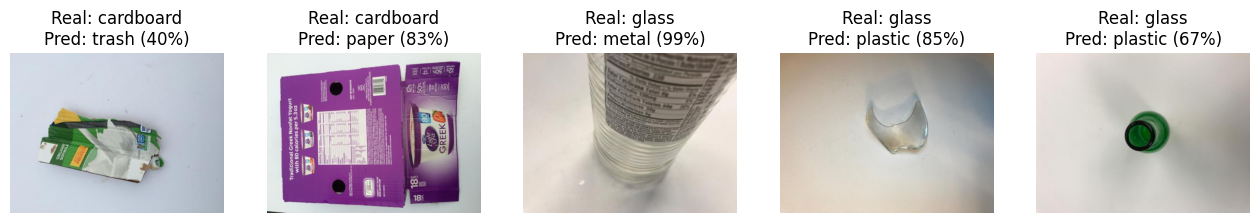

In [12]:
i = CLASES.index("trash")
fila_trash = confusion_matrix(y_test, pred_test)[i]
print(f"De {fila_trash.sum()} fotos de 'trash', el modelo acertó {fila_trash[i]}.")
for j, n in enumerate(fila_trash):
    if j != i and n > 0:
        print(f"  {n} se clasificaron como {CLASES[j]}")

rutas_test = [r for r, _ in ImageFolder(f"{DATOS}/test").samples]           # mismo orden que las predicciones
errores = np.where(pred_test != y_test)[0]
fig, ejes = plt.subplots(1, 5, figsize=(16, 3.5))
for eje, k in zip(ejes, errores[:5]):
    eje.imshow(Image.open(rutas_test[k])); eje.axis("off")
    eje.set_title(f"Real: {CLASES[y_test[k]]}\nPred: {CLASES[pred_test[k]]} ({probs_test[k].max():.0%})")
plt.show()

## 6. ¿Tiene sentido pedir revisión humana bajo 70 % de confianza?
La app avisa cuando la confianza es menor a 70 %. Revisamos en prueba si las predicciones con baja confianza realmente fallan más.

In [13]:
confianza = probs_test.max(1)
acierto = pred_test == y_test
print(f"Fotos con confianza ≥ 70 %: {(confianza >= .7).mean():.0%} · aciertan el {acierto[confianza >= .7].mean():.1%}")
print(f"Fotos con confianza < 70 %: {(confianza < .7).mean():.0%} · aciertan el {acierto[confianza < .7].mean():.1%}")

Fotos con confianza ≥ 70 %: 89% · aciertan el 93.2%
Fotos con confianza < 70 %: 11% · aciertan el 45.2%


## 7. Exportar el modelo para la app
Guardamos pesos + clases + preprocesamiento en un solo archivo, las métricas que muestra la app y 5 fotos de **prueba** como ejemplos.

In [14]:
r = resultados[elegido]
torch.save({"architecture": elegido, "classes": CLASES, "state_dict": r["modelo"].cpu().state_dict(),
            "data_config": r["config"]}, "/content/modelo/modelo.pt")

metricas = {"modelo_elegido": elegido, "n_prueba": int(len(y_test)),
            "accuracy": round(accuracy_score(y_test, pred_test), 4),
            "accuracy_balanceada": round(balanced_accuracy_score(y_test, pred_test), 4),
            "f1_macro": round(f1_score(y_test, pred_test, average="macro"), 4),
            "comparacion": json.loads(comparacion.to_json(orient="records")),
            "conteos": json.loads(conteos.to_json(orient="index"))}
json.dump(metricas, open("/content/modelo/metricas.json", "w"), indent=2, ensure_ascii=False)

os.makedirs("/content/ejemplos", exist_ok=True)
for clase in CLASES[:5]:                                                    # un ejemplo de prueba por clase
    shutil.copy(test[test.clase == clase].ruta.iloc[0], f"/content/ejemplos/{clase}.jpg")

shutil.make_archive("/content/para_la_app", "zip", "/content", "modelo")   # modelo/ → zip
shutil.make_archive("/content/ejemplos", "zip", "/content", "ejemplos")
print(json.dumps({k: v for k, v in metricas.items() if k not in ("conteos", "comparacion")}, indent=2))
try:
    from google.colab import files
    files.download("/content/para_la_app.zip"); files.download("/content/ejemplos.zip")
except ImportError:
    pass

{
  "modelo_elegido": "efficientnet_b0",
  "n_prueba": 379,
  "accuracy": 0.8786,
  "accuracy_balanceada": 0.8778,
  "f1_macro": 0.861
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones
*(Completar con los números obtenidos arriba.)*
- ¿Cuánto mejoró el transfer learning respecto de CLIP sin entrenar?
- ¿Por qué elegimos el modelo que elegimos?
- ¿Qué pasa con la clase `trash` y qué riesgo implica?
- ¿Qué mejoraríamos? (fotos reales con fondos sucios, más fotos de `trash`, validar fuera de TrashNet)